# Comparing label-free metrics on real data

You have unlabeled data and several anomaly detectors. Label-free metrics
try to tell you which detector works best without looking at labels. This
notebook computes every metric family in `labelfree` for a pool of
detectors on a real dataset, and then uses the labels, which the metrics
never saw, to check how well each metric ranks the detectors.

Install the dependencies with `pip install "labelfree[examples]"`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from oddball import load
from pyod.models.knn import KNN
from pyod.models.lof import LOF
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, clone
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

import labelfree as lf

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)

## Data

The Cardiotocography dataset has 21 features and about 10% anomalies. We
draw 300 rows, because IREOS trains one classifier per likely outlier, and
scale the features. The labels `y` stay untouched until the evaluation.

In [2]:
DATASET = "cardio"
CONTAMINATION = 0.10  # prior guess of the anomaly share, used by some metrics
rng = np.random.default_rng(0)

X_all, y_all = load(DATASET)
rows = rng.choice(len(X_all), size=300, replace=False)
X = StandardScaler().fit_transform(X_all[rows])
y = (y_all[rows] != 0).astype(int)
print(f"{X.shape[0]} samples, {X.shape[1]} features, {y.mean():.0%} anomalies")

300 samples, 21 features, 11% anomalies


## Candidate detectors

Four detector families with three settings each, plus two random scorers as
a sanity check: a useful metric should rank them at the bottom.

Detectors disagree on what a large score means. scikit-learn's
`decision_function` is larger for normal samples, PyOD's for anomalous
ones. Every `labelfree` function takes a `score_polarity` argument;
here we orient all scores once with `orient_scores` so that larger always
means more anomalous.

In [3]:
class RandomScorer(BaseEstimator):
    """Baseline that assigns uniform random scores."""

    def __init__(self, seed=0):
        self.seed = seed

    def fit(self, X):
        self.rng_ = np.random.default_rng(self.seed)
        return self

    def decision_function(self, X):
        return self.rng_.random(len(X))


candidates = {
    "iforest 32": IsolationForest(max_samples=32, random_state=0),
    "iforest 128": IsolationForest(max_samples=128, random_state=0),
    "iforest 256": IsolationForest(max_samples=256, random_state=0),
    "ocsvm 0.01": OneClassSVM(gamma=0.01),
    "ocsvm 0.1": OneClassSVM(gamma=0.1),
    "ocsvm 1": OneClassSVM(gamma=1.0),
    "lof 5": LOF(n_neighbors=5),
    "lof 20": LOF(n_neighbors=20),
    "lof 50": LOF(n_neighbors=50),
    "knn 5": KNN(n_neighbors=5),
    "knn 20": KNN(n_neighbors=20),
    "knn 50": KNN(n_neighbors=50),
    "random 1": RandomScorer(seed=1),
    "random 2": RandomScorer(seed=2),
}


def polarity(name):
    sklearn = name.startswith(("iforest", "ocsvm"))
    return "higher_is_normal" if sklearn else "higher_is_anomalous"


scores = {
    name: lf.orient_scores(
        model.fit(X).decision_function(X), score_polarity=polarity(name)
    )
    for name, model in candidates.items()
}
names = list(scores)
score_matrix = np.vstack(list(scores.values()))  # (n_models, n_samples)

## Computing the metrics

**Metrics on the score distribution.** RTM and EAG (AutoUAD) measure how far
the top scores stand out. `score_cluster_metrics` splits the scores at the
contamination level and returns ten internal clustering indices, of which
we keep three. These metrics compare raw score values, so they are most
meaningful between settings of the same detector.

In [4]:
metrics = pd.DataFrame(index=names)
metrics["rtm"] = [lf.relative_top_median_score(s) for s in score_matrix]
metrics["eag"] = [lf.expected_anomaly_gap_score(s) for s in score_matrix]
for index in ["silhouette", "davies_bouldin", "dunn"]:
    metrics[index] = [
        lf.score_cluster_metrics(s, contamination=CONTAMINATION, indices=[index])[index]
        for s in score_matrix
    ]

**Metrics in feature space.** These check whether the flagged samples
really differ from the rest: ASI and ASOI measure separation of the
flagged group, the Laplacian score checks that neighbors get similar
scores, and SIREOS and IREOS check that high-scoring samples are isolated.

SIREOS and IREOS weight samples by outlier probabilities. `unify_scores`
turns any score into a probability in `[0, 1]` (Kriegel et al., 2011).
`ireos_scores` evaluates all candidates with one shared kernel range, which
keeps them comparable. It is the slowest step in this notebook.

In [5]:
probabilities = np.vstack([lf.unify_scores(s) for s in score_matrix])

metrics["asi"] = [lf.asi_score(X, s, contamination=CONTAMINATION) for s in score_matrix]
metrics["asoi"] = [
    lf.asoi_score(X, s, contamination=CONTAMINATION) for s in score_matrix
]
metrics["laplacian"] = [lf.laplacian_score(X, s, n_neighbors=10) for s in score_matrix]
metrics["sireos"] = [lf.sireos_score(X, p) for p in probabilities]
metrics["ireos"] = lf.ireos_scores(X, probabilities)

With 21 features almost every sample is easy to isolate, so the IREOS
values of all candidates lie close together. `ireos_significance` puts a
value in context: it adjusts the index for chance, where 0 means no better
than flagging random samples, and tests it against random solutions. Each
call picks its own kernel range, so the index differs from the shared-range
values above.

In [6]:
pd.DataFrame(
    {
        name: vars(
            lf.ireos_significance(X, probabilities[names.index(name)], random_state=0)
        )
        for name in ["knn 20", "random 1"]
    }
).T.drop(columns="method").astype(float)

,index,expected,std,adjusted,z_score,p_value
knn 20,0.608,0.391,0.018,0.357,12.269,9.999e-05
random 1,0.765,0.774,0.005,-0.039,-1.699,9.491e-01


**Excess-Mass and Mass-Volume** compare each detector's level sets with a
uniform distribution over the bounding box of the data, so the detector
must also score uniform reference samples. Volume estimates break down in
high dimensions, so we follow Goix (2016): refit each detector on random
subsets of five features and average the results.

In [7]:
em = np.zeros(len(names))
mv = np.zeros(len(names))
n_subsets = 10
for _ in range(n_subsets):
    features = rng.choice(X.shape[1], size=5, replace=False)
    X_sub = X[:, features]
    reference = rng.uniform(X_sub.min(axis=0), X_sub.max(axis=0), size=(10_000, 5))
    volume = lf.bounding_box_volume(X_sub)
    for i, (name, model) in enumerate(candidates.items()):
        model = clone(model).fit(X_sub)
        args = (model.decision_function(X_sub), model.decision_function(reference))
        kwargs = {"support_volume": volume, "score_polarity": polarity(name)}
        em[i] += lf.excess_mass_auc(*args, **kwargs) / n_subsets
        mv[i] += lf.mass_volume_auc(*args, **kwargs) / n_subsets
metrics["em"], metrics["mv"] = em, mv

**Consensus between candidates** needs only the score matrix. It rewards
candidates that rank the samples like the others do. UDR compares each
candidate with the other settings of its own family.

In [8]:
family = [name.split()[0] for name in names]
metrics["mc"] = lf.model_centrality_scores(score_matrix)
metrics["udr"] = lf.udr_scores(score_matrix, family)
metrics["hits"] = lf.hits_scores(score_matrix)
metrics["ens"] = lf.ens_scores(score_matrix)

**Ranking stability** refits each detector on random halves of the data
and checks that its top-ranked samples stay the same.

In [9]:
def seed_param(name, run):
    if name.startswith("iforest"):
        return {"random_state": run}
    return {"seed": run} if name.startswith("random") else {}


def stability(name, n_runs=20):
    runs = []
    for run in range(n_runs):
        half = np.random.default_rng(run).choice(len(X), len(X) // 2, replace=False)
        model = clone(candidates[name]).set_params(**seed_param(name, run))
        runs.append(model.fit(X[half]).decision_function(X))
    return lf.ranking_stability_score(
        np.vstack(runs), contamination=CONTAMINATION, score_polarity=polarity(name)
    )


metrics["stability"] = [stability(name) for name in names]

## All metrics at a glance

One row per candidate. Arrows show which direction is better.

In [10]:
higher_is_better = {
    "rtm": True,
    "eag": True,
    "silhouette": True,
    "davies_bouldin": False,
    "dunn": True,
    "asi": True,
    "asoi": True,
    "laplacian": False,
    "sireos": False,
    "ireos": True,
    "em": True,
    "mv": False,
    "mc": True,
    "udr": True,
    "hits": True,
    "ens": True,
    "stability": True,
}
metrics.rename(columns=lambda c: f"{c} {'↑' if higher_is_better[c] else '↓'}")

,rtm ↑,eag ↑,silhouette ↑,davies_bouldin ↓,dunn ↑,asi ↑,asoi ↑,laplacian ↓,sireos ↓,ireos ↑,em ↑,mv ↓,mc ↑,udr ↑,hits ↑,ens ↑,stability ↑
iforest 32,-3.468,0.960,0.603,0.434,2.725e-03,1.081,4.339,0.401,0.034,0.798,4.700e+10,68.634,0.517,0.942,0.300,0.577,0.956
iforest 128,-2.230,1.127,0.631,0.478,4.603e-04,1.139,4.359,0.445,0.030,0.799,5.620e+10,63.712,0.538,0.958,0.318,0.597,0.970
iforest 256,-1.835,1.200,0.646,0.472,6.176e-03,0.918,4.318,0.470,0.030,0.801,7.503e+10,56.619,0.537,0.952,0.326,0.598,0.969
ocsvm 0.01,-263188.965,1.454,0.718,0.494,1.821e-02,1.125,4.453,0.444,0.024,0.790,3.741e+10,119.619,0.492,0.504,0.336,0.562,0.998
ocsvm 0.1,270473.209,0.915,0.584,0.388,3.558e-03,1.272,4.423,0.555,0.029,0.811,3.775e+10,85.883,0.530,0.510,0.293,0.612,0.965
ocsvm 1,-10.868,0.013,0.082,0.690,5.938e-05,0.268,2.427,0.999,0.091,0.801,1.511e+11,11.125,0.052,0.088,0.033,0.160,0.531
lof 5,0.386,1.503,0.721,0.491,7.006e-03,0.345,3.144,0.929,0.060,0.818,5.642e+10,124.055,0.237,0.444,0.114,0.328,0.789
lof 20,0.451,1.122,0.672,0.568,2.374e-03,0.933,4.115,0.591,0.030,0.798,4.698e+10,113.181,0.516,0.716,0.274,0.600,0.985
lof 50,0.619,1.322,0.736,0.572,8.307e-03,1.137,4.386,0.452,0.022,0.796,4.672e+10,108.714,0.543,0.649,0.289,0.616,0.998
knn 5,1.411,1.120,0.677,0.563,1.558e-02,1.249,4.405,0.434,0.028,0.820,7.496e+10,47.602,0.441,0.793,0.313,0.505,0.981


## Checking the metrics against the labels

Now we use the labels. Average precision (AP) measures how well each
candidate actually ranks the anomalies. For each metric we report

- the Spearman correlation between the metric and AP across candidates,
  after flipping lower-is-better metrics so that positive is good,
- the candidate the metric would pick, and that candidate's AP,
- and the best rank the metric gives a random scorer (1 is best, 14 worst).

In [11]:
ap = pd.Series([average_precision_score(y, s) for s in score_matrix], index=names)
oriented = metrics.apply(lambda col: col if higher_is_better[col.name] else -col)

evaluation = pd.DataFrame(
    {
        "spearman_with_ap": oriented.apply(lambda col: spearmanr(col, ap).statistic),
        "pick": oriented.idxmax(),
        "pick_ap": ap[oriented.idxmax()].to_numpy(),
        "best_random_rank": oriented.rank(ascending=False)
        .loc[["random 1", "random 2"]]
        .min()
        .astype(int),
    }
).sort_values("spearman_with_ap", ascending=False)
print(
    f"AP of the candidates: best {ap.max():.3f} ({ap.idxmax()}), "
    f"median {ap.median():.3f}, worst {ap.min():.3f} ({ap.idxmin()})"
)
evaluation

AP of the candidates: best 0.657 (ocsvm 0.01), median 0.549, worst 0.094 (random 2)


,spearman_with_ap,pick,pick_ap,best_random_rank
stability,0.807,knn 50,0.653,13
hits,0.807,knn 20,0.586,13
mc,0.785,knn 50,0.653,13
sireos,0.780,lof 50,0.646,13
laplacian,0.763,knn 50,0.653,12
asoi,0.763,knn 20,0.586,12
eag,0.666,lof 5,0.145,12
ens,0.648,lof 50,0.646,13
udr,0.618,iforest 128,0.626,13
silhouette,0.604,lof 50,0.646,12


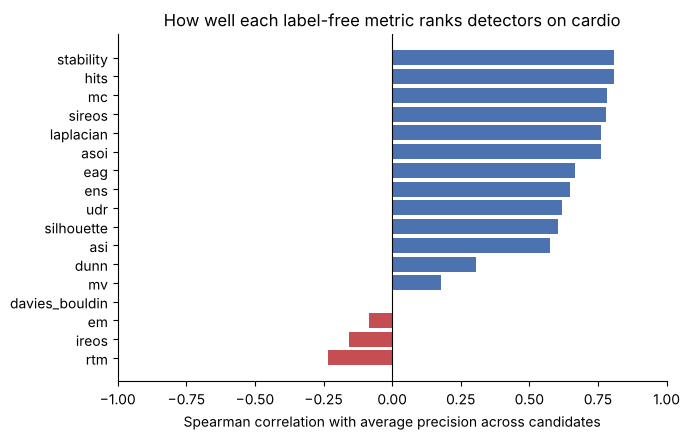

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = np.where(evaluation["spearman_with_ap"] > 0, "#4C72B0", "#C44E52")
ax.barh(
    evaluation.index[::-1], evaluation["spearman_with_ap"][::-1], color=colors[::-1]
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel("Spearman correlation with average precision across candidates")
ax.set_title(f"How well each label-free metric ranks detectors on {DATASET}")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

## Reading the results

- Positive correlations mean the metric ranks detectors roughly like their
  true quality. Metrics that put the random scorers last at least pass the
  sanity check.
- Score-distribution metrics compare raw score values across detector
  families with different scales, which often hurts them in a mixed pool.
- This is one dataset and one sample. Ma et al. (2023) found that no
  label-free metric reliably beats a well-chosen default across many
  datasets. Treat these values as evidence and check them across splits;
  the [model selection notebook](model_selection.ipynb) does that for a
  tuning workflow.